# City Lifestyle Segmentation

This is a synthetic dataset of 300 cities. Each row has the city name, country, and lifestyle measures like population density, income, rent, internet access, air quality, public transport, happiness and green space. There is no target column. We'll look into the data, check how the features relate, scale the numeric columns and use KMeans to group cities with a similar lifestyle, then see what separates the clusters.

In [18]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

df = pd.read_csv("city_lifestyle_dataset.csv")
df.head()

,city_name,country,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
0,Old Vista,Europe,2775,3850,86.4,1310,43,52.0,8.5,23.8
1,Beachport,Europe,3861,3700,78.1,1330,42,62.8,8.1,33.1
2,Valleyborough,Europe,2562,4310,80.1,1330,39,73.2,8.5,40.2
3,City,Europe,3192,3970,81.2,1480,60,49.2,8.5,43.6
4,Falls,Europe,3496,4320,100.0,1510,64,93.7,8.5,42.5


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city_name               300 non-null    object 
 1   country                 300 non-null    object 
 2   population_density      300 non-null    int64  
 3   avg_income              300 non-null    int64  
 4   internet_penetration    300 non-null    float64
 5   avg_rent                300 non-null    int64  
 6   air_quality_index       300 non-null    int64  
 7   public_transport_score  300 non-null    float64
 8   happiness_score         300 non-null    float64
 9   green_space_ratio       300 non-null    float64
dtypes: float64(4), int64(4), object(2)
memory usage: 23.6+ KB


In [20]:
df.describe()

,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,3944.843333,2827.200000,74.305333,1002.766667,71.246667,55.717333,6.644000,33.993333
std,2982.566777,1201.163939,17.014492,456.282066,25.344961,14.712549,1.685864,9.434067
min,100.000000,480.000000,34.000000,170.000000,22.000000,15.000000,2.500000,2.000000
25%,1830.000000,1907.500000,64.400000,640.000000,54.000000,46.075000,5.300000,28.225000
50%,3083.500000,2810.000000,75.000000,990.000000,67.500000,54.700000,6.900000,34.700000
75%,4823.750000,3752.500000,87.225000,1332.500000,86.000000,64.200000,8.500000,40.400000
max,14427.000000,5720.000000,100.000000,2430.000000,146.000000,95.000000,8.500000,58.000000


In [21]:
df.isnull().sum()

city_name                 0
country                   0
population_density        0
avg_income                0
internet_penetration      0
avg_rent                  0
air_quality_index         0
public_transport_score    0
happiness_score           0
green_space_ratio         0
dtype: int64

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df["country"].value_counts()

country
Asia             80
Europe           60
North America    50
South America    40
Africa           35
Oceania          35
Name: count, dtype: int64

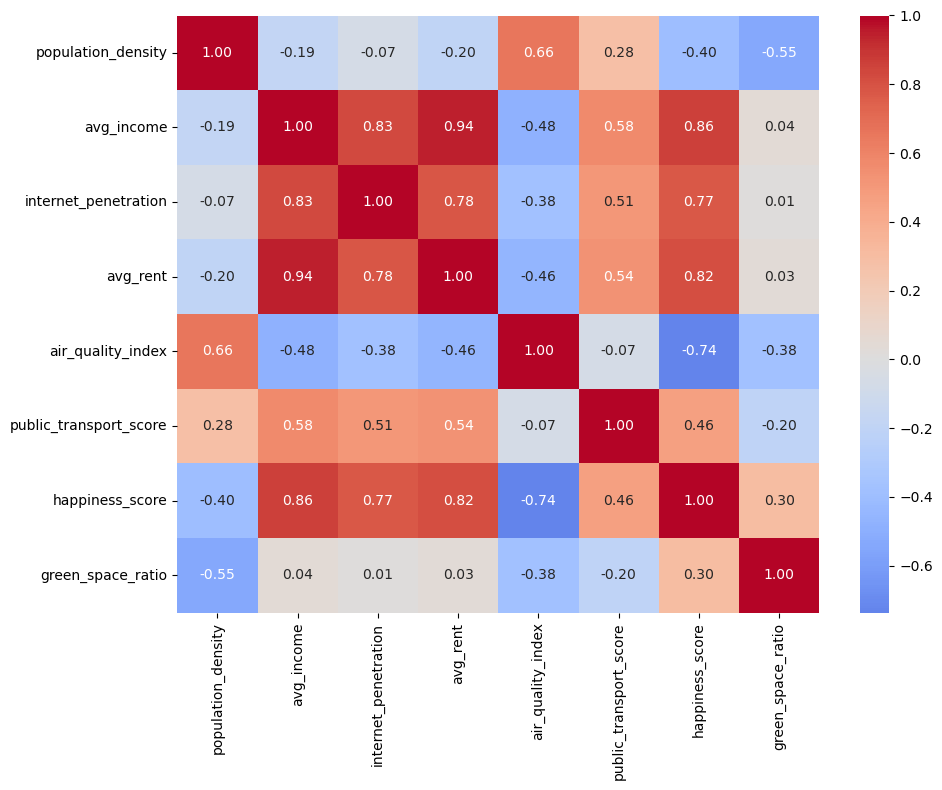

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

num = df.drop(columns=["city_name", "country"])

plt.figure(figsize=(10, 8))
sns.heatmap(num.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.tight_layout()
plt.show()

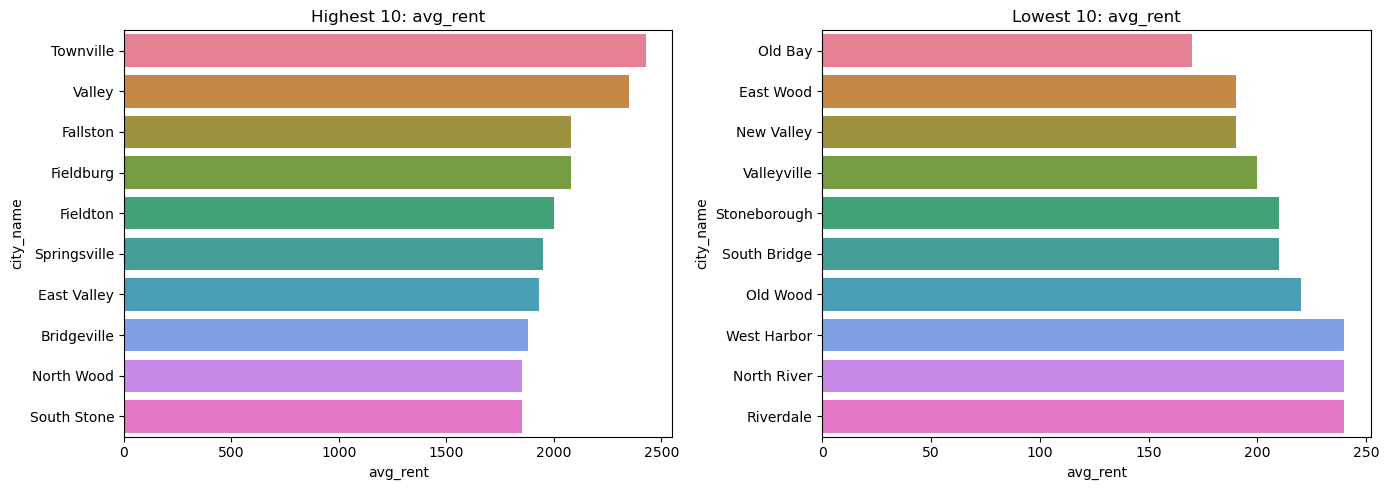

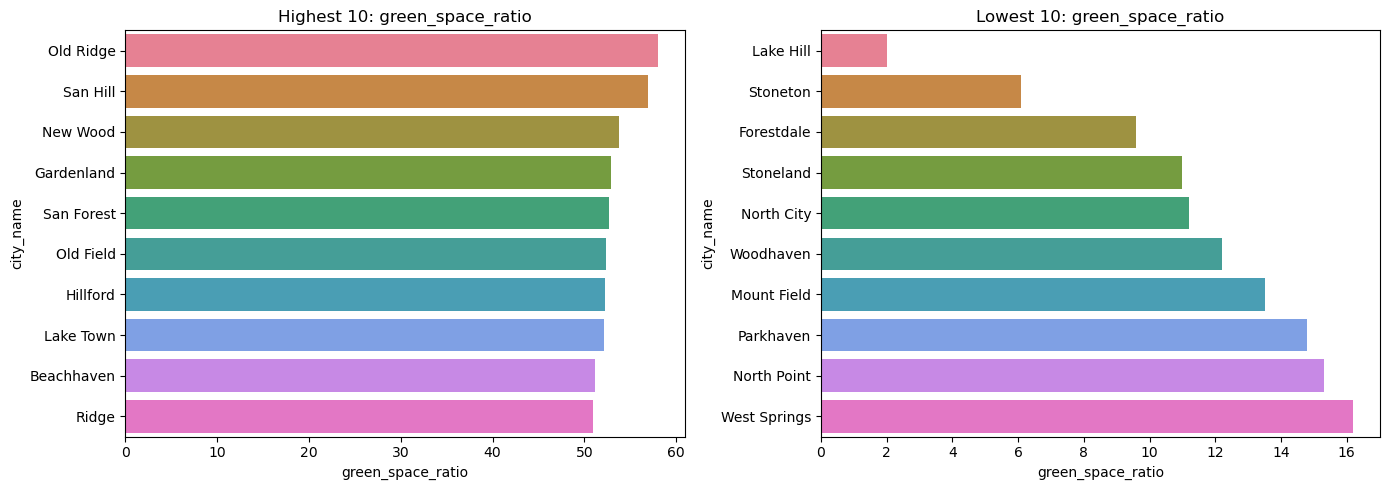

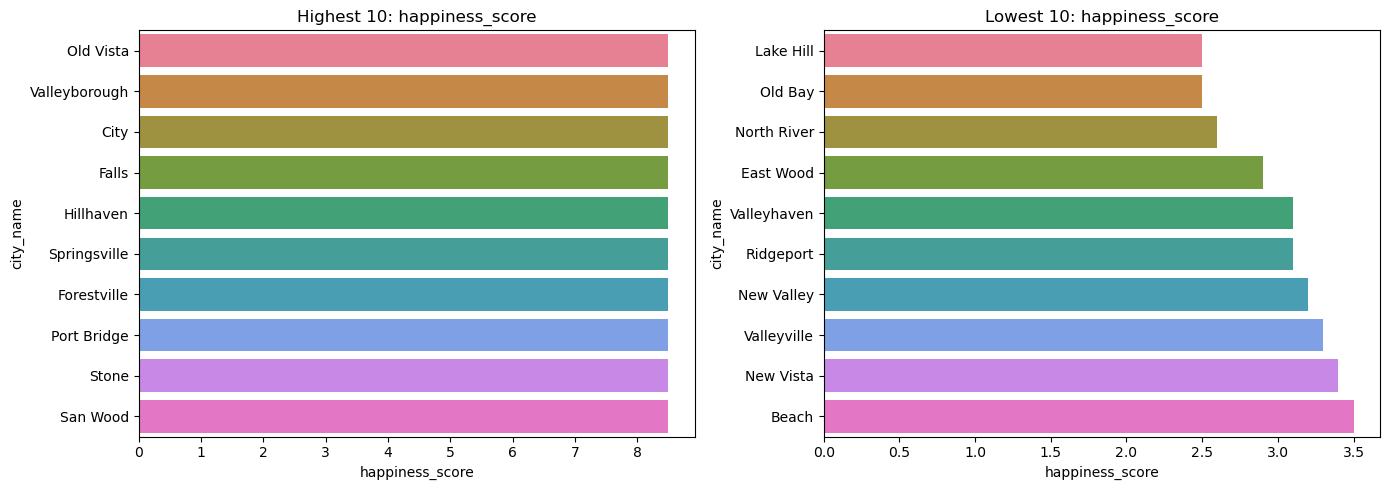

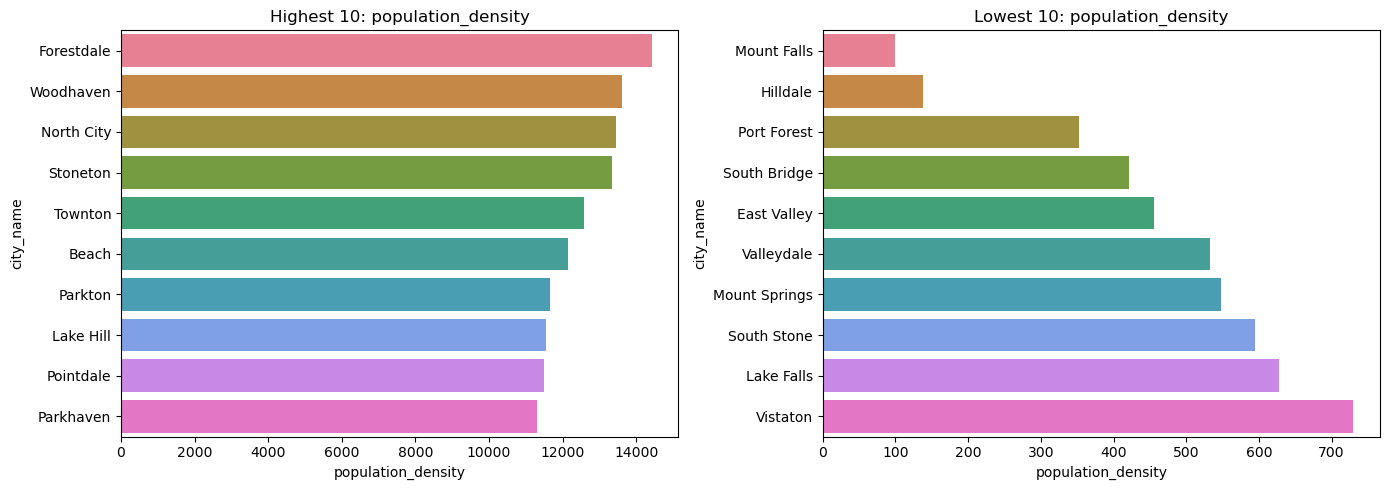

In [25]:
def top_bottom_bar(data, col, n=10, xlabel=None):
    top = data.nlargest(n, col)
    low = data.nsmallest(n, col)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.barplot(data=top, x=col, y="city_name", hue="city_name", palette="husl", legend=False, dodge=False, ax=axes[0])
    axes[0].set_title(f"Highest {n}: {col}")
    axes[0].set_xlabel(xlabel or col)

    sns.barplot(data=low, x=col, y="city_name", hue="city_name", palette="husl", legend=False, dodge=False, ax=axes[1])
    axes[1].set_title(f"Lowest {n}: {col}")
    axes[1].set_xlabel(xlabel or col)

    plt.tight_layout()
    plt.show()

top_bottom_bar(df, "avg_rent")
top_bottom_bar(df, "green_space_ratio")
top_bottom_bar(df, "happiness_score")
top_bottom_bar(df, "population_density")

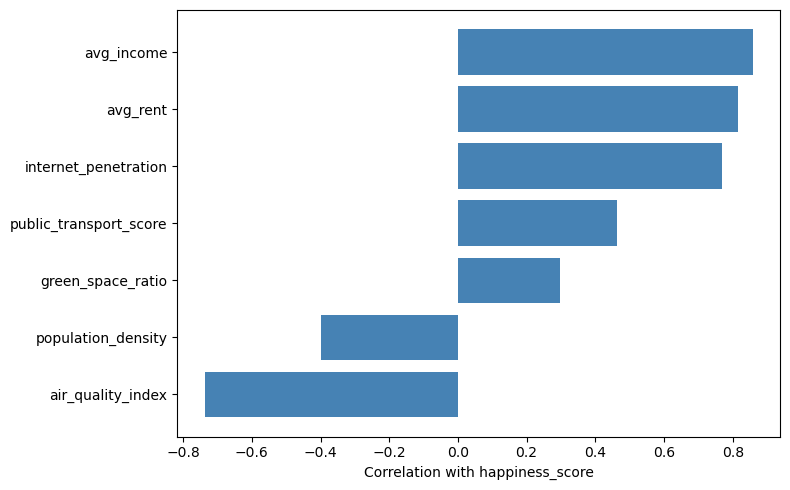

In [26]:
rel = num.corr(numeric_only=True)["happiness_score"].drop("happiness_score").sort_values()

plt.figure(figsize=(8, 5))
plt.barh(rel.index, rel.values, color="steelblue")
plt.xlabel("Correlation with happiness_score")
plt.tight_layout()
plt.show()

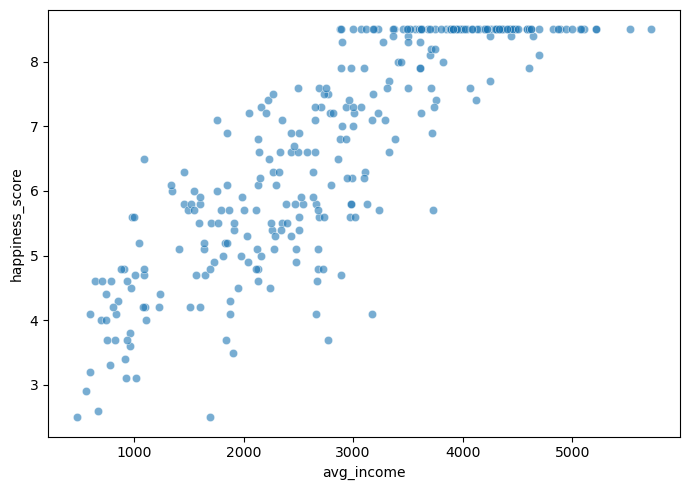

In [27]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="avg_income", y="happiness_score", alpha=0.6)
plt.tight_layout()
plt.show()

In [28]:
from sklearn.preprocessing import StandardScaler

features = [
    "population_density", "avg_income", "internet_penetration", "avg_rent",
    "air_quality_index", "public_transport_score", "happiness_score", "green_space_ratio",
]

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

Elbow k: 4


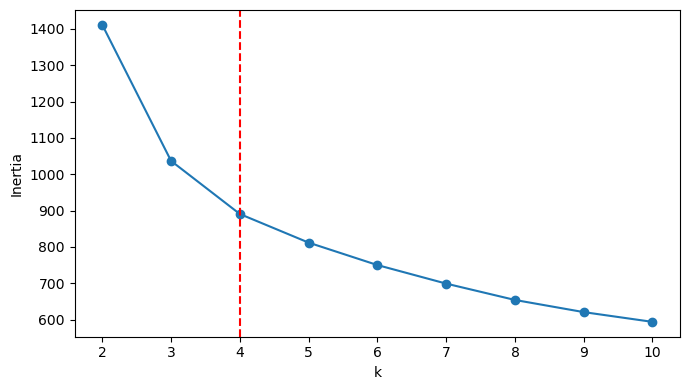

KMeans silhouette: 0.27


In [29]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from kneed import KneeLocator

inertias = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

kl = KneeLocator(range(2, 11), inertias, curve="convex", direction="decreasing")
k_elbow = kl.elbow
print("Elbow k:", k_elbow)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), inertias, marker="o")
plt.axvline(k_elbow, color="red", linestyle="--")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.tight_layout()
plt.show()

kmeans = KMeans(n_clusters=k_elbow, random_state=42, n_init=10)
df["cluster_kmeans"] = kmeans.fit_predict(X_scaled)
print("KMeans silhouette:", round(silhouette_score(X_scaled, df["cluster_kmeans"]), 3))

In [31]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=k_elbow)
df["cluster_agg"] = agg.fit_predict(X_scaled)
print("Agglomerative silhouette:", silhouette_score(X_scaled, df["cluster_agg"]))

Agglomerative silhouette: 0.2655672016719954


In [32]:
df.groupby("cluster_kmeans")[features].mean().round(2)

,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
cluster_kmeans,,,,,,,,
0,9690.68,2564.55,73.39,887.27,108.00,64.35,5.25,22.25
1,4226.28,2524.27,73.46,899.88,72.98,54.98,6.63,35.04
2,2160.94,4083.18,88.92,1463.36,50.37,62.84,8.39,36.74
3,2700.08,1237.19,50.90,422.34,79.64,38.48,4.62,36.00


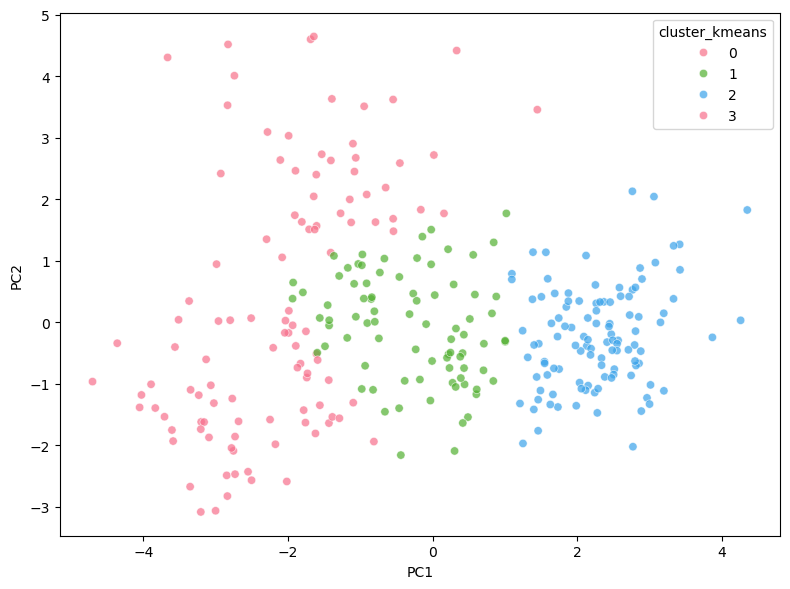

In [33]:
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=42).fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=df["cluster_kmeans"], palette="husl", alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

In [34]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=k_elbow)
df["cluster_agg"] = agg.fit_predict(X_scaled)

sk_k = silhouette_score(X_scaled, df["cluster_kmeans"])
sk_a = silhouette_score(X_scaled, df["cluster_agg"])

print(f"KMeans silhouette:       {sk_k:.3f}")
print(f"Agglomerative silhouette: {sk_a:.3f}")

KMeans silhouette:       0.270
Agglomerative silhouette: 0.266


# Conclusion

I explored 300 cities with income, rent, density, air quality, transport, internet, happiness and green space. I checked the correlation heatmap, ranked cities on rent and other indicators, and looked at how happiness relates to income and the other features. I scaled the numeric features and clustered with KMeans; the elbow method chose 4 clusters and the silhouette score was about 0.27, so the lifestyle groups overlap more than in simpler datasets but still show structure. I compared KMeans and Agglomerative clustering with the same k using silhouette scores to see which split the cities more clearly. PCA helped visualize the cluster assignments in two dimensions without changing the clustering itself.